# Симуляции свойств метода

Как часто z-тест находит эффект при параметрах из `docs/preregistration.md` и что происходит при нарушении предпосылок. Параметры по умолчанию: базовая конверсия 10%, 63 000 на группу, alpha 0.05, 21 день по 6000 пользователей (по 3000 в группу в день). Код симуляций — `src/abtest/simulate.py`. Ошибка Монте-Карло для доли около 5% при R повторах — $\sqrt{0.05 \cdot 0.95 / R}$: 0.31 п.п. при 5000.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from abtest.simulate import (
    power_empirical, power_analytic, daily_tests, peeking_fpr, first_stop,
    clustered_aa, design_effect, srm_bug, fwer, welch_coverage, boot_coverage, mean_coverage,
)

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a8a"
P, N, ALPHA, DAILY, DAYS, R = 0.10, 63000, 0.05, 6000, 21, 5000
BE, MDE = 0.00365, 0.005


def mc_err(x, reps):
    return np.sqrt(x * (1 - x) / reps)

## а) A/A, фиксированный горизонт

Проверяем, что z-тест с пулом при отсутствии эффекта ошибается с частотой alpha. Конверсии генерируются как биномиальные счётчики по 63 000 в группе, 5000 повторов.

ложных срабатываний: 4.48% ± 0.29% (ожидаемо 5%, 95% диапазон МК 4.4–5.6%)


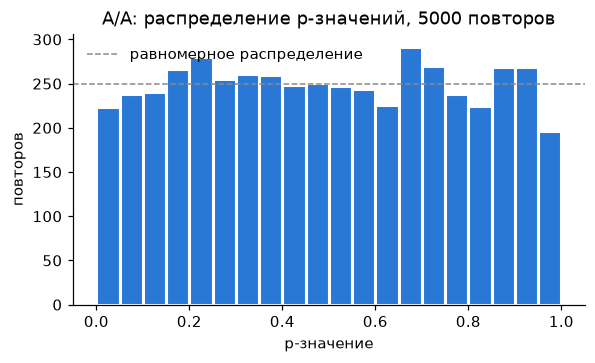

In [2]:
from abtest.stats import diff_proportions

rng = np.random.default_rng(0)
xc, xt = rng.binomial(N, P, R), rng.binomial(N, P, R)
aa = diff_proportions(xc, N, xt, N)
fpr = (aa.p_value < ALPHA).mean()
print(f"ложных срабатываний: {fpr:.2%} ± {mc_err(fpr, R):.2%} (ожидаемо 5%, 95% диапазон МК 4.4–5.6%)")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(aa.p_value, bins=20, range=(0, 1), color=BLUE, edgecolor="white", linewidth=2)
ax.axhline(R / 20, color=GRAY, ls="--", lw=1, label="равномерное распределение")
ax.set_xlabel("p-значение")
ax.set_ylabel("повторов")
ax.set_title("A/A: распределение p-значений, 5000 повторов")
ax.legend(frameon=False)
plt.show()

**Вывод.** Доля ложных срабатываний 4.48% — внутри 95%-го диапазона Монте-Карло 4.4–5.6%, p-значения распределены равномерно: при фиксированном горизонте тест калиброван.

## б) Мощность

Доля значимых результатов при истинном эффекте 0, +0.365 п.п. (безубыточность), +0.5 п.п. (MDE), +0.8 п.п. и кривая по эффекту от 0 до 1 п.п. Аналитическая мощность — нормальная аппроксимация для z-теста с пулом.

In [3]:
key = np.array([0, BE, MDE, 0.008])
pw = pd.DataFrame({
    "эффект, п.п.": key * 100,
    "эмпирическая": power_empirical(key, P, N, R, ALPHA, seed=1),
    "аналитическая": power_analytic(key, P, N, ALPHA),
})
pw["ошибка МК"] = mc_err(pw["эмпирическая"], R)
pw

,"эффект, п.п.",эмпирическая,аналитическая,ошибка МК
0,0.0000,0.0486,0.0500,0.0030
1,0.3650,0.5756,0.5723,0.0070
2,0.5000,0.8320,0.8329,0.0053
3,0.8000,0.9950,0.9964,0.0010


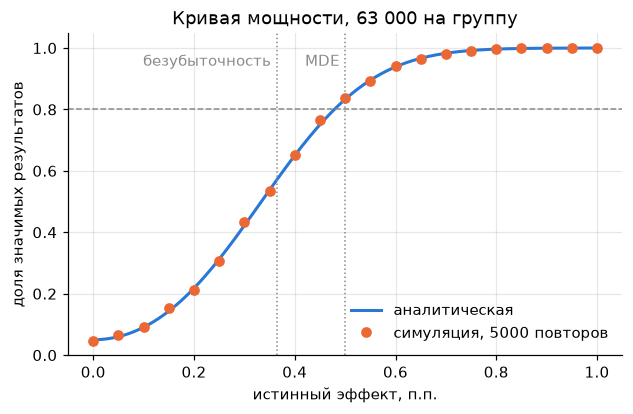

In [4]:
grid = np.linspace(0, 0.01, 21)
emp = power_empirical(grid, P, N, R, ALPHA, seed=2)
fine = np.linspace(0, 0.01, 201)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(fine * 100, power_analytic(fine, P, N, ALPHA), color=BLUE, lw=2, label="аналитическая")
ax.plot(grid * 100, emp, "o", color=ORANGE, ms=6, label=f"симуляция, {R} повторов")
for x, name in [(BE, "безубыточность"), (MDE, "MDE")]:
    ax.axvline(x * 100, color=GRAY, ls=":", lw=1)
    ax.annotate(name, (x * 100, 0.98), xytext=(-4, 0), textcoords="offset points", ha="right", va="top", color=GRAY)
ax.axhline(0.8, color=GRAY, ls="--", lw=1)
ax.set_xlabel("истинный эффект, п.п.")
ax.set_ylabel("доля значимых результатов")
ax.set_title("Кривая мощности, 63 000 на группу")
ax.legend(frameon=False, loc="lower right")
ax.grid(alpha=0.3)
plt.show()

**Вывод.** Эмпирическая мощность совпадает с аналитической в пределах ошибки Монте-Карло: 83.2% на MDE (аналитически 83.3%) и 57.6% на безубыточном эффекте (57.2%), то есть окупающийся эффект 0.37 п.п. тест пропустит примерно в 4 случаях из 10.

## в) Подглядывание

A/A, проверка после каждого дня набора (по 3000 пользователей в группу в день), остановка при первом p < 0.05. Для k проверок берутся k равномерно расставленных дней с последней проверкой на день 21; k = 1 — фиксированный горизонт. Конверсия считается наблюдаемой сразу, окно 7 дней не моделируется.

In [5]:
aa_diff, aa_p = daily_tests(0.0, P, DAILY, DAYS, R, seed=3)
curve = peeking_fpr(aa_p, ALPHA)
print(f"фиксированный горизонт: {curve[0]:.2%}, ежедневные проверки (21): {curve[-1]:.2%} ± {mc_err(curve[-1], R):.2%}")
pd.DataFrame({"проверок": [1, 3, 7, 21], "ложных срабатываний": curve[[0, 2, 6, 20]]})

фиксированный горизонт: 4.96%, ежедневные проверки (21): 24.66% ± 0.61%


,проверок,ложных срабатываний
0,1,0.0496
1,3,0.1054
2,7,0.1664
3,21,0.2466


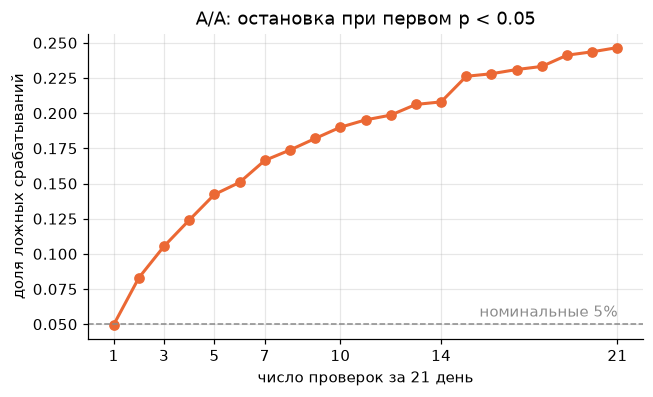

In [6]:
k = np.arange(1, DAYS + 1)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(k, curve, "o-", color=ORANGE, lw=2, ms=6)
ax.axhline(ALPHA, color=GRAY, ls="--", lw=1)
ax.annotate("номинальные 5%", (DAYS, ALPHA), xytext=(0, 5), textcoords="offset points", ha="right", color=GRAY)
ax.set_xticks([1, 3, 5, 7, 10, 14, 21])
ax.set_xlabel("число проверок за 21 день")
ax.set_ylabel("доля ложных срабатываний")
ax.set_title("A/A: остановка при первом p < 0.05")
ax.grid(alpha=0.3)
plt.show()

**Вывод.** При ежедневных проверках ложное срабатывание происходит в 24.7% A/A-тестов вместо 5%; рост идёт уже с нескольких проверок (10.5% при 3, 16.6% при 7), поэтому предрегистрация запрещает досрочную остановку по эффективности.

## г) Проклятие победителя

Истинный эффект +0.5 п.п., ежедневные проверки, остановка при первом p < 0.05. Сравниваются оценки эффекта у остановившихся досрочно (день 1–20) и оценки на фиксированном горизонте (день 21, все повторы). Для справки — фиксированный горизонт только среди значимых результатов.

In [7]:
w_diff, w_p = daily_tests(MDE, P, DAILY, DAYS, R, seed=4)
day, est = first_stop(w_diff, w_p, ALPHA)
early = (day > 0) & (day < DAYS)
fixed = w_diff[:, -1]
sig = w_p[:, -1] < ALPHA
wc = pd.DataFrame({
    "повторов": [early.sum(), R, sig.sum()],
    "средняя оценка, п.п.": [est[early].mean() * 100, fixed.mean() * 100, fixed[sig].mean() * 100],
}, index=["досрочная остановка", "фиксированный горизонт", "фиксированный, только p < 0.05"])
wc["смещение, п.п."] = wc["средняя оценка, п.п."] - MDE * 100
wc["относительно эффекта"] = wc["смещение, п.п."] / (MDE * 100)
print(f"медианный день остановки: {np.median(day[early]):.0f}")
wc

медианный день остановки: 6


,повторов,"средняя оценка, п.п.","смещение, п.п.",относительно эффекта
досрочная остановка,4446,0.8290,0.3290,0.6580
фиксированный горизонт,5000,0.4947,-0.0053,-0.0106
"фиксированный, только p < 0.05",4135,0.5479,0.0479,0.0959


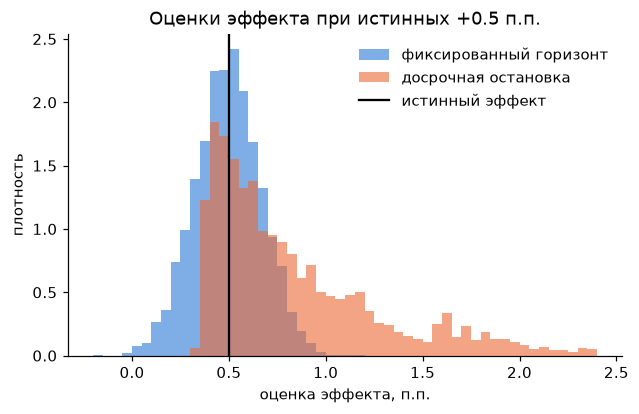

In [8]:
bins = np.linspace(-0.2, 2.4, 53)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(fixed * 100, bins=bins, color=BLUE, alpha=0.6, label="фиксированный горизонт", density=True)
ax.hist(est[early] * 100, bins=bins, color=ORANGE, alpha=0.6, label="досрочная остановка", density=True)
ax.axvline(MDE * 100, color="black", lw=1.5, label="истинный эффект")
ax.set_xlabel("оценка эффекта, п.п.")
ax.set_ylabel("плотность")
ax.set_title("Оценки эффекта при истинных +0.5 п.п.")
ax.legend(frameon=False)
plt.show()

**Вывод.** Остановившиеся досрочно (89% повторов, медиана — день 6) завышают эффект в среднем на +0.33 п.п., то есть на две трети истинного: ранняя остановка случается только при случайно большой оценке. На фиксированном горизонте оценка несмещённая (−0.005 п.п.); отбор только значимых результатов даёт и там небольшое завышение (+0.05 п.п.), потому что мощность меньше 100%.

## д) Единица анализа

A/A. У пользователя 1–8 сессий (равномерно), склонность к покупке в сессии $p_i \sim \text{Beta}(a, b)$ со средним 10% и ICC = 1/(a + b + 1) = 0.1, покупки в сессиях — Binomial($m_i$, $p_i$). Метрика — конверсия сессии в покупку. Сравниваются z-тест по сессиям как независимым наблюдениям и дельта-метод для ratio-метрики по пользователям; точечная оценка у них одна и та же, различается только стандартная ошибка. 63 000 пользователей в группе, 2000 повторов (каждый повтор — около 570 тыс. сессий на группу).

In [9]:
ICC, M_MAX, RC = 0.1, 8, 2000
cl = clustered_aa(P, ICC, M_MAX, N, RC, seed=5)
m = np.arange(1, M_MAX + 1)
m_bar, m_w = m.mean(), (m**2).mean() / m.mean()
emp_ratio = cl.diff.var() / cl.var_session.mean()
ud = pd.DataFrame({
    "ложных срабатываний": [(cl.p_session < ALPHA).mean(), (cl.p_user < ALPHA).mean()],
    "истинная дисперсия / заявленная": [emp_ratio, cl.diff.var() / cl.var_user.mean()],
}, index=["по сессиям (z-тест)", "по пользователям (дельта-метод)"])
ud["ошибка МК"] = mc_err(ud["ложных срабатываний"], RC)
ud

,ложных срабатываний,истинная дисперсия / заявленная,ошибка МК
по сессиям (z-тест),0.1065,1.5194,0.0069
по пользователям (дельта-метод),0.0565,1.0360,0.0052


In [10]:
pd.DataFrame({
    "значение": [emp_ratio, design_effect(ICC, m_bar), design_effect(ICC, m_w)],
}, index=[
    "эмпирическое отношение дисперсий",
    f"1 + (m̄ − 1)·ICC, m̄ = {m_bar:.2f}",
    f"1 + (E[m²]/E[m] − 1)·ICC, E[m²]/E[m] = {m_w:.2f}",
])

,значение
эмпирическое отношение дисперсий,1.5194
"1 + (m̄ − 1)·ICC, m̄ = 4.50",1.3500
"1 + (E[m²]/E[m] − 1)·ICC, E[m²]/E[m] = 5.67",1.4667


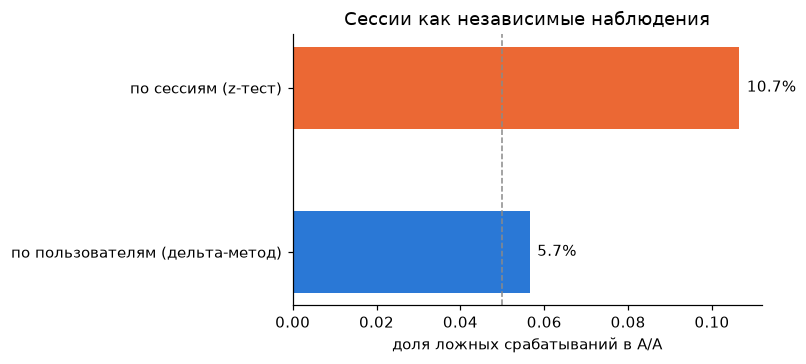

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
vals = ud["ложных срабатываний"]
ax.barh(vals.index, vals, color=[ORANGE, BLUE], height=0.5)
for i, v in enumerate(vals):
    ax.annotate(f"{v:.1%}", (v, i), xytext=(5, 0), textcoords="offset points", va="center")
ax.axvline(ALPHA, color=GRAY, ls="--", lw=1)
ax.set_xlabel("доля ложных срабатываний в A/A")
ax.set_title("Сессии как независимые наблюдения")
ax.invert_yaxis()
plt.show()

**Вывод.** Анализ по сессиям занижает дисперсию примерно в 1.5 раза и даёт 10.7% ложных срабатываний вместо 5%; дельта-метод по пользователям калиброван (5.7% при ошибке МК 0.5 п.п., отношение дисперсий 1.04). Эмпирическое отношение 1.52 (стандартная ошибка выборочной дисперсии по 2000 повторам около 3%, то есть ±0.05) совпадает с design effect при взвешенном размере кластера E[m²]/E[m] = 5.67 (1.47), а не при m̄ = 4.5 (1.35): формула с m̄ верна для кластеров одинакового размера, а при разном числе сессий пользователи с многими сессиями вносят непропорционально большой вклад в дисперсию.

## е) SRM из-за бага

Истинного эффекта нет. Сегмент — 12% пользователей с конверсией 3% (остальные — 10.95%, чтобы общая конверсия была 10%). В treatment из-за бага теряется половина сегмента: эти пользователи не попадают в выгрузку. Смотрим смещение наивной оценки, долю «значимых» z-тестов и долю срабатываний `srm_test` (p < 0.001).

In [12]:
sb = srm_bug(P, 0.12, 0.03, 0.5, N, R, seed=6)
p_rest = (P - 0.12 * 0.03) / 0.88
p_t = (0.06 * 0.03 + 0.88 * p_rest) / 0.94
pd.DataFrame({
    "значение": [N * 0.94, sb.n_t.mean(), (p_t - P) * 100, sb.diff.mean() * 100,
                 (sb.p_value < ALPHA).mean(), sb.srm.mean()],
}, index=["ожидаемый размер treatment", "средний размер treatment",
          "ожидаемое смещение, п.п.", "среднее смещение наивной оценки, п.п.",
          "доля p < 0.05 у z-теста", "доля срабатываний srm_test"])

,значение
ожидаемый размер treatment,59220.0000
средний размер treatment,59219.7872
"ожидаемое смещение, п.п.",0.4468
"среднее смещение наивной оценки, п.п.",0.4438
доля p < 0.05 у z-теста,0.7342
доля срабатываний srm_test,1.0000


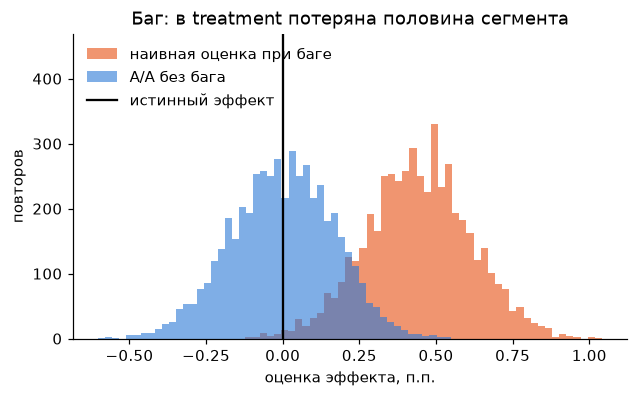

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(sb.diff * 100, bins=50, color=ORANGE, alpha=0.7, label="наивная оценка при баге")
ax.hist(aa.diff * 100, bins=50, color=BLUE, alpha=0.6, label="A/A без бага")
ax.axvline(0, color="black", lw=1.5, label="истинный эффект")
ax.set_xlabel("оценка эффекта, п.п.")
ax.set_ylabel("повторов")
ax.set_title("Баг: в treatment потеряна половина сегмента")
ax.set_ylim(top=ax.get_ylim()[1] * 1.35)
ax.legend(frameon=False, loc="upper left")
plt.show()

**Вывод.** Потеря 6% пользователей с низкой конверсией создаёт фиктивный эффект +0.44 п.п. (ожидаемо 0.45) — почти MDE — и z-тест «находит» его в 73% случаев. `srm_test` ловит баг во всех повторах: дисбаланс 63 000 против примерно 59 200 далеко за порогом, поэтому SRM-проверка до анализа обязательна.

## ж) Множественные сравнения

Пять метрик без эффекта. Под H0 z-статистика каждой метрики распределена как N(0, 1), поэтому генерируются сразу векторы z-статистик с попарной корреляцией 0 или 0.5. FWER — доля повторов, где хотя бы одна метрика значима. 20 000 повторов: Холм при глобальной нуль-гипотезе отвергает что-то, только если min p ≤ alpha/5, поэтому его теоретический FWER при независимости 1 − 0.99⁵ = 4.9% близок к границе 5%, и нужна меньшая ошибка Монте-Карло.

In [14]:
RF = 20000
rows = {}
for rho in [0.0, 0.5]:
    raw, adj = fwer(5, rho, RF, ALPHA, seed=7)
    rows[f"корреляция {rho}"] = {"без поправки": raw, "Холм": adj}
mc = pd.DataFrame(rows).T
mc.loc["теория при независимости"] = [1 - 0.95**5, 1 - 0.99**5]
print(f"ошибка МК около 5%: {mc_err(0.05, RF):.2%}, около 22.6%: {mc_err(0.226, RF):.2%}")
mc

ошибка МК около 5%: 0.15%, около 22.6%: 0.30%


,без поправки,Холм
корреляция 0.0,0.2275,0.0504
корреляция 0.5,0.1777,0.0435
теория при независимости,0.2262,0.0490


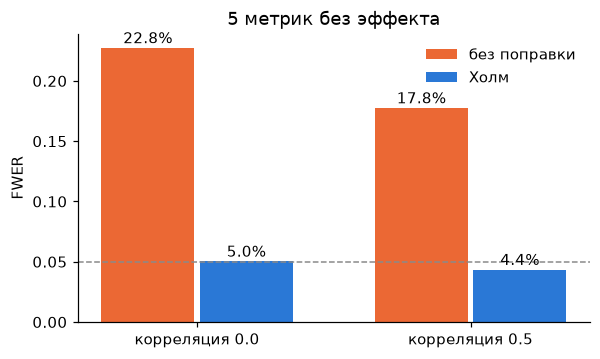

In [15]:
fig, ax = plt.subplots(figsize=(6, 3.4))
x = np.arange(2)
sim = mc.iloc[:2]
ax.bar(x - 0.18, sim["без поправки"], 0.34, color=ORANGE, label="без поправки")
ax.bar(x + 0.18, sim["Холм"], 0.34, color=BLUE, label="Холм")
for i, (a, b) in enumerate(sim.values):
    ax.annotate(f"{a:.1%}", (i - 0.18, a), xytext=(0, 3), textcoords="offset points", ha="center")
    ax.annotate(f"{b:.1%}", (i + 0.18, b), xytext=(0, 3), textcoords="offset points", ha="center")
ax.axhline(ALPHA, color=GRAY, ls="--", lw=1)
ax.set_xticks(x, sim.index)
ax.set_ylabel("FWER")
ax.set_title("5 метрик без эффекта")
ax.legend(frameon=False)
plt.show()

**Вывод.** Без поправки хотя бы одна из пяти метрик «значима» в 22.8% случаев (теория 22.6%), Холм держит FWER около 5% (5.04% при теоретических 4.9% и ошибке МК 0.15 п.п.). При корреляции 0.5 метрики ошибаются совместно, поэтому FWER без поправки ниже — 17.8%, а Холм становится консервативнее — 4.4%.

## з) Тяжёлые хвосты

ARPU = покупка (10%) × логнормальная сумма со средним 2500 ₽ и коэффициентом вариации 1 или 3. A/A, истинная разница 0. Покрытие 95%-го CI Уэлча (5000 повторов) и перцентильного бутстрепа (2000 повторов по 1000 бутстреп-выборок) при 200, 1000, 5000, 63 000 на группу.

Бутстреп эквивалентен `bootstrap_diff` по всем пользователям, но ресэмплирует только покупателей: число покупателей в бутстреп-выборке ~ Binomial(n, k/n), их суммы берутся с возвращением из k наблюдаемых. Это в 10 раз дешевле и даёт то же распределение (проверка — `tests/test_simulate.py`).

Для сравнения добавлено покрытие t-интервала для среднего ARPU одной группы. В таблице и на графике — 95%-й интервал ошибки Монте-Карло ±1.96·√(p(1−p)/R).

In [16]:
RW, RB, NB = 5000, 2000, 1000
ns, cvs = [200, 1000, 5000, 63000], [1, 3]
reps = {"Уэлч, разница": RW, "бутстреп, разница": RB, "t, среднее одной группы": RW}
cov = pd.DataFrame([
    {"n": n, "CV": cv,
     "Уэлч, разница": welch_coverage(n, cv, RW, seed=8),
     "бутстреп, разница": boot_coverage(n, cv, RB, NB, seed=9),
     "t, среднее одной группы": mean_coverage(n, cv, RW, seed=10)}
    for cv in cvs for n in ns
]).set_index(["CV", "n"])
half = pd.DataFrame({k: 1.96 * mc_err(cov[k], r) for k, r in reps.items()})
cov.combine(half, lambda c, h: c.map("{:.1%}".format) + " ± " + h.map("{:.1%}".format))

Уэлч, разница бутстреп, разница t, среднее одной группы
CV n                                                            
1  200    95.4% ± 0.6%      93.7% ± 1.1%            90.8% ± 0.8%
   1000   94.6% ± 0.6%      94.0% ± 1.0%            93.8% ± 0.7%
   5000   95.1% ± 0.6%      95.0% ± 1.0%            94.9% ± 0.6%
   63000  95.3% ± 0.6%      93.5% ± 1.1%            94.9% ± 0.6%
3  200    97.3% ± 0.5%      92.0% ± 1.2%            77.0% ± 1.2%
   1000   95.7% ± 0.6%      92.2% ± 1.2%            87.2% ± 0.9%
   5000   95.6% ± 0.6%      93.5% ± 1.1%            90.7% ± 0.8%
   63000  95.6% ± 0.6%      94.0% ± 1.0%            94.2% ± 0.6%

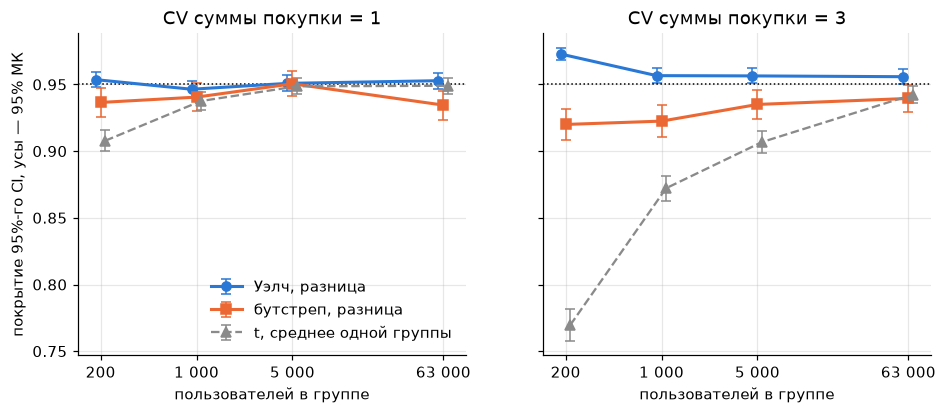

In [17]:
style = {
    "Уэлч, разница": dict(fmt="o-", color=BLUE, lw=2, shift=0.92),
    "бутстреп, разница": dict(fmt="s-", color=ORANGE, lw=2, shift=1.0),
    "t, среднее одной группы": dict(fmt="^--", color=GRAY, lw=1.5, shift=1.08),
}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, cv in zip(axes, cvs):
    for k, s in style.items():
        ax.errorbar(np.array(ns) * s["shift"], cov.loc[cv, k], yerr=half.loc[cv, k], fmt=s["fmt"],
                    color=s["color"], lw=s["lw"], ms=6, capsize=3, elinewidth=1, label=k)
    ax.axhline(0.95, color="black", ls=":", lw=1)
    ax.set_xscale("log")
    ax.set_xticks(ns, [f"{n:,}".replace(",", " ") for n in ns])
    ax.minorticks_off()
    ax.set_xlabel("пользователей в группе")
    ax.set_title(f"CV суммы покупки = {cv}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("покрытие 95%-го CI, усы — 95% МК")
axes[0].legend(frameon=False, loc="lower right")
plt.show()

**Вывод.** В A/A асимметрия двух одинаково распределённых средних взаимно гасится, разница симметрична, и Уэлч не теряет покрытие, а при тяжёлых хвостах становится консервативным: 97.3% ± 0.5% при n = 200 и CV 3, около 95.5% при больших n. Проблема тяжёлых хвостов видна там, где асимметрия не гасится: t-интервал для среднего одной группы при CV 3 покрывает 77.0% при n = 200 и 87.2% при n = 1000, при CV 1 — 90.8% при n = 200. Перцентильный бутстреп недопокрывает при малых n и сильной асимметрии: 92.0–93.5% при CV 3 до n = 5000. С ростом n все интервалы приближаются к 95%.

Бутстреп при n = 63 000 и CV 1 с seed 9 даёт 93.5% ± 1.1% — интервал не включает 95%. Диагностика (вне ноутбука, `boot_coverage(63000, 1, 2000, 1000, seed=s)` для s = 9…13; в бюджет времени `make simulations` не помещается):

| seed | 9 | 10 | 11 | 12 | 13 |
|---|---|---|---|---|---|
| покрытие бутстрепа | 93.5% ± 1.1% | 95.3% ± 0.9% | 95.2% ± 0.9% | 94.8% ± 1.0% | 95.0% ± 1.0% |
| покрытие Уэлча на тех же данных | 93.5% | 95.3% | 95.5% | 95.1% | 95.3% |

Среднее по пяти seed — 94.7%; разброс между seed 0.74 п.п. против биномиальных 0.50 п.п., χ²(4) = 8.8, p = 0.07 — значимо не больше биномиального, то есть корреляции повторов не видно. Ресемплинг корректен: бутстреп-SD в каждом seed совпадает с SE Уэлча (6.15 против 6.14 при теоретической 6.14), число покупателей в бутстреп-выборке случайно, индексы между повторами, группами и ячейками не переиспользуются. Независимая сверка через `bootstrap_diff` по всем пользователям — 95.5% ± 1.4% на 800 повторах. Низкое покрытие при seed 9 создают сами данные, а не бутстреп: разброс разниц ARPU в этой последовательности на 9% выше теоретического, и Уэлч на тех же данных даёт те же 93.5%; на 2 × 20 000 других повторах генератор даёт дисперсию 1.006 и 0.995 от теоретической.

Ячейки с CV 1 и CV 3 при одном n используют одни и те же случайные числа (то же число покупателей и те же нормальные величины), поэтому они коррелированы и не подтверждают друг друга независимо.